# Cell 1: Environment Setup

In [1]:
!pip install effdet timm albumentations pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.5/112.5 kB 4.5 MB/s eta 0:00:00


# Cell 2: Imports and Dataset Mapping

In [2]:
import os
import glob
import cv2
import torch
import gc
import numpy as np
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch.transforms import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from effdet import get_efficientdet_config, EfficientDet, DetBenchTrain
from effdet.efficientdet import HeadNet

# Locate the TFP-BD dataset
BASE_KAGGLE_INPUT = "/kaggle/input"
INPUT_DATASET_PATH = None
for root, dirs, files in os.walk(BASE_KAGGLE_INPUT):
    if 'tfp_dataset' in dirs:
        INPUT_DATASET_PATH = os.path.join(root, 'tfp_dataset')
        break

if not INPUT_DATASET_PATH:
    raise FileNotFoundError("Could not find 'tfp_dataset'. Make sure it is mounted.")
print(f"Dataset located at: {INPUT_DATASET_PATH}")

Dataset located at: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset


# Cell 3: Dataset Adapter

In [3]:
# CLASSES = ["Car", "Bus", "Truck", "Motorcycle", "Bicycle", "Rickshaw", "Mini-Truck", "CNG", "Pedestrian"]
# NUM_CLASSES = len(CLASSES)
# IMG_SIZE = 640
# BATCH_SIZE = 8

# class YoloToEffDetDataset(Dataset):
#     def __init__(self, split_dir, img_size=IMG_SIZE, transforms=None):
#         self.img_dir = os.path.join(split_dir, 'images')
#         self.label_dir = os.path.join(split_dir, 'labels')
#         self.img_files = sorted(glob.glob(os.path.join(self.img_dir, '*.*')))
#         self.img_size = img_size
#         self.transforms = transforms

#     def __len__(self):
#         return len(self.img_files)

#     def __getitem__(self, idx):
#         img_path = self.img_files[idx]
#         image = cv2.imread(img_path)
#         image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
#         h, w, _ = image.shape

#         label_path = os.path.join(self.label_dir, os.path.splitext(os.path.basename(img_path))[0] + '.txt')
#         boxes = []
#         labels = []

#         if os.path.exists(label_path):
#             with open(label_path, 'r') as f:
#                 for line in f.readlines():
#                     cls_id, xc, yc, bw, bh = map(float, line.strip().split())
                    
#                     xmin = (xc - bw / 2) * w
#                     ymin = (yc - bh / 2) * h
#                     xmax = (xc + bw / 2) * w
#                     ymax = (yc + bh / 2) * h
                    
#                     # Clip coordinates to strictly fit inside the image frame
#                     xmin = max(0.0, min(float(w), xmin))
#                     ymin = max(0.0, min(float(h), ymin))
#                     xmax = max(0.0, min(float(w), xmax))
#                     ymax = max(0.0, min(float(h), ymax))

#                     if xmax > xmin and ymax > ymin:
#                         boxes.append([xmin, ymin, xmax, ymax])
#                         labels.append(int(cls_id) + 1)

#         boxes = np.array(boxes, dtype=np.float32) if len(boxes) > 0 else np.zeros((0, 4), dtype=np.float32)
#         labels = np.array(labels, dtype=np.int64) if len(labels) > 0 else np.zeros((0,), dtype=np.int64)

#         if self.transforms:
#             transformed = self.transforms(image=image, bboxes=boxes, labels=labels)
#             image = transformed['image']
#             boxes = np.array(transformed['bboxes'], dtype=np.float32)
#             labels = np.array(transformed['labels'], dtype=np.int64)

#         if len(boxes) > 0:
#             boxes = boxes[:, [1, 0, 3, 2]]
#         else:
#             boxes = np.zeros((0, 4), dtype=np.float32)

#         return image, {'bboxes': torch.tensor(boxes, dtype=torch.float32), 'labels': torch.tensor(labels, dtype=torch.int64)}

# Cell 4: DataLoader and Model Configuration

In [4]:
# import os
# # Configure PyTorch to manage fragmented VRAM more efficiently
# os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

# IMG_SIZE = 640
# BATCH_SIZE = 4 # Reduced from 8 to safely fit the 15GB VRAM limit

# def collate_fn(batch):
#     images, targets = zip(*batch)
#     images = torch.stack(images, dim=0)
#     max_boxes = max(len(t['bboxes']) for t in targets)
#     max_boxes = max(max_boxes, 1)

#     batch_boxes = torch.zeros((len(targets), max_boxes, 4), dtype=torch.float32)
#     batch_labels = torch.zeros((len(targets), max_boxes), dtype=torch.int64)

#     for i, t in enumerate(targets):
#         n = len(t['bboxes'])
#         if n > 0:
#             batch_boxes[i, :n] = t['bboxes']
#             batch_labels[i, :n] = t['labels']

#     return images, {'bbox': batch_boxes, 'cls': batch_labels}

# train_transforms = A.Compose([
#     A.Resize(height=IMG_SIZE, width=IMG_SIZE),
#     A.HorizontalFlip(p=0.5),
#     A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
#     ToTensorV2()
# ], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['labels']))

# train_dataset = YoloToEffDetDataset(f"{INPUT_DATASET_PATH}/train", transforms=train_transforms)
# train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, collate_fn=collate_fn)

# config = get_efficientdet_config('tf_efficientdet_d3')
# config.image_size = (IMG_SIZE, IMG_SIZE)
# config.num_classes = NUM_CLASSES

# net = EfficientDet(config, pretrained_backbone=True)
# net.class_net = HeadNet(config, num_outputs=NUM_CLASSES)
# model = DetBenchTrain(net, config)

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# model.to(device)

# Cell 5: Training Execution

In [5]:
# import gc

# if torch.cuda.is_available():
#     torch.cuda.empty_cache()
#     gc.collect()

# os.makedirs('/kaggle/working/runs/effdet_d3', exist_ok=True)
# optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
# scaler = torch.amp.GradScaler('cuda')

# epochs = 30
# ACCUMULATION_STEPS = 4 # 4 batch size * 4 steps = effective batch size of 16
# loss_history = []
# print("Starting EfficientDet-D3 Training Sequence with Aggressive Accumulation...")

# for epoch in range(epochs):
#     model.train()
#     running_loss = 0.0
    
#     optimizer.zero_grad() 

#     for step, (images, targets) in enumerate(train_loader):
#         images = images.to(device)
#         targets = {k: v.to(device) for k, v in targets.items()}

#         with torch.amp.autocast('cuda'):
#             loss_dict = model(images, targets)
#             loss = loss_dict['loss']
#             loss = loss / ACCUMULATION_STEPS 

#         scaler.scale(loss).backward()

#         if (step + 1) % ACCUMULATION_STEPS == 0 or (step + 1) == len(train_loader):
#             scaler.step(optimizer)
#             scaler.update()
#             optimizer.zero_grad()

#         running_loss += loss.item() * ACCUMULATION_STEPS 

#     scheduler.step()
#     avg_loss = running_loss / len(train_loader)
#     loss_history.append(avg_loss)
#     print(f"Epoch [{epoch + 1}/{epochs}] - Loss: {avg_loss:.4f}")

#     if (epoch + 1) % 5 == 0:
#         torch.save(model.model.state_dict(), f'/kaggle/working/runs/effdet_d3/effdet_d3_epoch_{epoch + 1}.pth')

# print("Training Complete! Weights securely saved.")

# Cell 6: Performance Visualization

In [6]:
# plt.figure(figsize=(10, 6))
# plt.plot(range(1, epochs + 1), loss_history, marker='o', linestyle='-', color='b', label='Training Loss')
# plt.title('EfficientDet-D3 Training Loss Curve')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()
# plt.grid(True)
# plt.savefig('/kaggle/working/runs/effdet_d3/training_loss.png')
# plt.show()

In [7]:
import os
import glob
import cv2
import torch
import numpy as np
import albumentations as A
from albumentations.pytorch.transforms import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from effdet import get_efficientdet_config, EfficientDet
from effdet.efficientdet import HeadNet

# Locate Dataset
BASE_KAGGLE_INPUT = "/kaggle/input"
INPUT_DATASET_PATH = None
for root, dirs, files in os.walk(BASE_KAGGLE_INPUT):
    if 'tfp_dataset' in dirs:
        INPUT_DATASET_PATH = os.path.join(root, 'tfp_dataset')
        break

CLASSES = ["Car", "Bus", "Truck", "Motorcycle", "Bicycle", "Rickshaw", "Mini-Truck", "CNG", "Pedestrian"]
NUM_CLASSES = len(CLASSES)
IMG_SIZE = 640
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Rebuild Dataset Adapter
class YoloToEffDetDataset(Dataset):
    def __init__(self, split_dir, img_size=IMG_SIZE, transforms=None):
        self.img_dir = os.path.join(split_dir, 'images')
        self.label_dir = os.path.join(split_dir, 'labels')
        self.img_files = sorted(glob.glob(os.path.join(self.img_dir, '*.*')))
        self.transforms = transforms

    def __len__(self): return len(self.img_files)

    def __getitem__(self, idx):
        img_path = self.img_files[idx]
        image = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        h, w, _ = image.shape

        label_path = os.path.join(self.label_dir, os.path.splitext(os.path.basename(img_path))[0] + '.txt')
        boxes, labels = [], []

        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                for line in f.readlines():
                    cls_id, xc, yc, bw, bh = map(float, line.strip().split())
                    xmin = max(0.0, min(float(w), (xc - bw / 2) * w))
                    ymin = max(0.0, min(float(h), (yc - bh / 2) * h))
                    xmax = max(0.0, min(float(w), (xc + bw / 2) * w))
                    ymax = max(0.0, min(float(h), (yc + bh / 2) * h))

                    if xmax > xmin and ymax > ymin:
                        boxes.append([xmin, ymin, xmax, ymax])
                        labels.append(int(cls_id) + 1)

        boxes = np.array(boxes, dtype=np.float32) if len(boxes) > 0 else np.zeros((0, 4), dtype=np.float32)
        labels = np.array(labels, dtype=np.int64) if len(labels) > 0 else np.zeros((0,), dtype=np.int64)

        if self.transforms:
            transformed = self.transforms(image=image, bboxes=boxes, labels=labels)
            image = transformed['image']
            boxes = np.array(transformed['bboxes'], dtype=np.float32)
            labels = np.array(transformed['labels'], dtype=np.int64)

        boxes = boxes[:, [1, 0, 3, 2]] if len(boxes) > 0 else np.zeros((0, 4), dtype=np.float32)
        return image, {'bboxes': torch.tensor(boxes, dtype=torch.float32), 'labels': torch.tensor(labels, dtype=torch.int64)}

def collate_fn(batch):
    images, targets = zip(*batch)
    images = torch.stack(images, dim=0)
    max_boxes = max(1, max(len(t['bboxes']) for t in targets))
    batch_boxes = torch.zeros((len(targets), max_boxes, 4), dtype=torch.float32)
    batch_labels = torch.zeros((len(targets), max_boxes), dtype=torch.int64)

    for i, t in enumerate(targets):
        n = len(t['bboxes'])
        if n > 0:
            batch_boxes[i, :n] = t['bboxes']
            batch_labels[i, :n] = t['labels']
    return images, {'bbox': batch_boxes, 'cls': batch_labels}

# Rebuild Config
config = get_efficientdet_config('tf_efficientdet_d3')
config.image_size = (IMG_SIZE, IMG_SIZE)
config.num_classes = NUM_CLASSES

In [8]:
from effdet import DetBenchPredict
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from tqdm import tqdm

# 1. Validation Transforms (No random flipping or aggressive augmentations)
val_transforms = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
], bbox_params=A.BboxParams(format='pascal_voc', label_fields=['labels']))

# Rebuild dataset pointing to the Validation split
val_dataset = YoloToEffDetDataset(f"{INPUT_DATASET_PATH}/val", transforms=val_transforms)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2, collate_fn=collate_fn)

# 2. Initialize Inference Model
print("Loading EfficientDet-D3 weights for evaluation...")
net = EfficientDet(config, pretrained_backbone=False)
net.class_net = HeadNet(config, num_outputs=NUM_CLASSES)

# Load your finalized weights from the Kaggle output directory
weights_path = '//kaggle/input/notebooks/sharminaktermukta/efficientdet-d3-model-training/runs/effdet_d3/effdet_d3_epoch_30.pth'
net.load_state_dict(torch.load(weights_path, map_location=device))

# DetBenchPredict handles Non-Maximum Suppression (NMS) for clean bounding boxes
bench = DetBenchPredict(net)
bench.to(device)
bench.eval()

# 3. Setup COCO Metrics Calculator
metric = MeanAveragePrecision(box_format='xyxy', class_metrics=True)

print("Evaluating against the Validation Set. This may take a few minutes...")

with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="Validating"):
        images = images.to(device)
        batch_size = images.shape[0]
        
        # effdet inference requires explicit scale/size info to map boxes correctly
        img_scales = torch.tensor([1.0] * batch_size, dtype=torch.float32).to(device)
        img_sizes = torch.tensor([[IMG_SIZE, IMG_SIZE]] * batch_size, dtype=torch.float32).to(device)
        
        # CORRECTED: Keys must exactly match 'img_scale' and 'img_size'
        img_info = {'img_scale': img_scales, 'img_size': img_sizes}
        
        # Forward pass
        outputs = bench(images, img_info) 
        
        preds = []
        target_list = []
        
        for i in range(batch_size):
            # Process Predictions (effdet outputs: xmin, ymin, xmax, ymax, score, class)
            pred = outputs[i]
            valid_mask = pred[:, 4] > 0.01  # Filter out extremely low-confidence background noise
            valid_pred = pred[valid_mask]
            
            preds.append(dict(
                boxes=valid_pred[:, 0:4].cpu(),
                scores=valid_pred[:, 4].cpu(),
                labels=valid_pred[:, 5].to(torch.int64).cpu()
            ))
            
            # Process Targets (Convert our dataset's yxyx back to standard xyxy)
            t_boxes_yxyx = targets['bbox'][i]
            t_labels = targets['cls'][i]
            
            valid_t_mask = t_labels > 0
            t_boxes_yxyx = t_boxes_yxyx[valid_t_mask]
            t_labels = t_labels[valid_t_mask]
            
            if len(t_boxes_yxyx) > 0:
                t_boxes_xyxy = t_boxes_yxyx[:, [1, 0, 3, 2]] 
            else:
                t_boxes_xyxy = torch.zeros((0, 4))
            
            target_list.append(dict(
                boxes=t_boxes_xyxy.cpu(),
                labels=t_labels.cpu()
            ))
            
        metric.update(preds, target_list)

# 4. Compute and Print Final Thesis Metrics
print("\nCalculating Final Performance Metrics...")
metrics = metric.compute()

print("-" * 40)
print("EFFICIENTDET-D3 VALIDATION RESULTS")
print("-" * 40)
print(f"mAP@50-95 (Mean Average Precision): {metrics['map'].item():.4f}")
print(f"mAP@50 (Standard Precision):      {metrics['map_50'].item():.4f}")
print(f"mAR@100 (Standard Recall):        {metrics['mar_100'].item():.4f}")
print("-" * 40)

Loading EfficientDet-D3 weights for evaluation...
Evaluating against the Validation Set. This may take a few minutes...


Validating: 100%|██████████| 1184/1184 [03:01<00:00,  6.53it/s]



Calculating Final Performance Metrics...
----------------------------------------
EFFICIENTDET-D3 VALIDATION RESULTS
----------------------------------------
mAP@50-95 (Mean Average Precision): 0.4362
mAP@50 (Standard Precision):      0.6663
mAR@100 (Standard Recall):        0.6525
----------------------------------------


Training loss image not found. Ensure the path matches your Kaggle output.

--- CONFUSION MATRIX ---


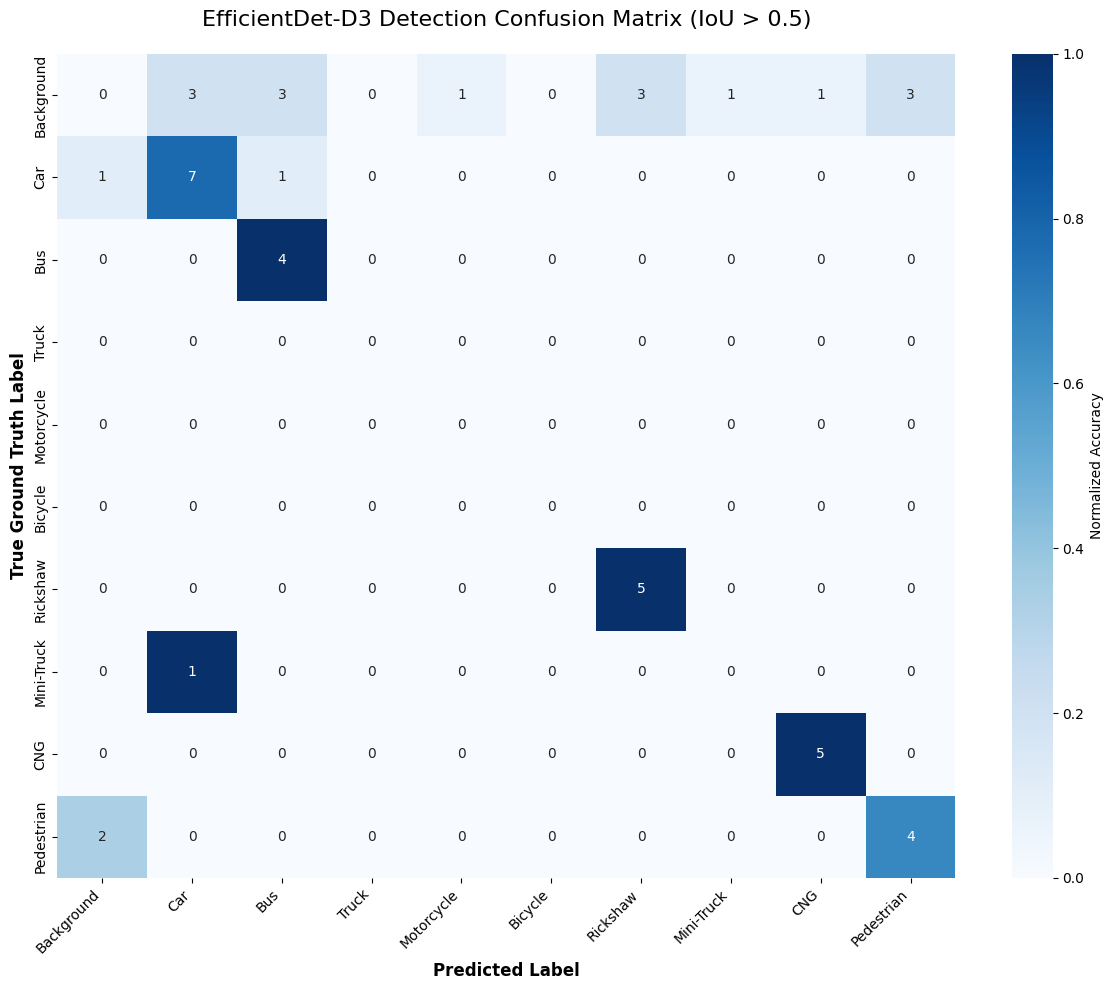

In [9]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from torchvision.ops import box_iou

# 1. Display the Training Loss Curve from the background run
loss_img_path = '/kaggle/working/runs/effdet_d3/training_loss.png' # Update path if necessary based on your Kaggle output directory
if os.path.exists(loss_img_path):
    print("--- TRAINING CURVE ---")
    plt.figure(figsize=(10, 6))
    img = mpimg.imread(loss_img_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()
else:
    print("Training loss image not found. Ensure the path matches your Kaggle output.")

# 2. Generate the Bounding Box Confusion Matrix
print("\n--- CONFUSION MATRIX ---")
# Add Background class (index 0) to your existing classes
eval_classes = ['Background'] + CLASSES
num_eval_classes = len(eval_classes)
conf_matrix = np.zeros((num_eval_classes, num_eval_classes), dtype=np.int32)

conf_threshold = 0.25
iou_threshold = 0.5

# Iterate through the predictions and targets generated in Cell 7
for i in range(len(preds)):
    pred_boxes = preds[i]['boxes']
    pred_labels = preds[i]['labels']
    pred_scores = preds[i]['scores']
    
    gt_boxes = target_list[i]['boxes']
    gt_labels = target_list[i]['labels']
    
    # Filter predictions by confidence threshold
    keep_mask = pred_scores > conf_threshold
    pred_boxes = pred_boxes[keep_mask]
    pred_labels = pred_labels[keep_mask]
    
    # Handle empty ground truths or empty predictions
    if len(gt_boxes) == 0 and len(pred_boxes) == 0:
        continue
    if len(gt_boxes) == 0:
        for pl in pred_labels:
            conf_matrix[0, pl.item()] += 1  # False Positive (Background classified as Object)
        continue
    if len(pred_boxes) == 0:
        for gl in gt_labels:
            conf_matrix[gl.item(), 0] += 1  # False Negative (Object missed)
        continue
        
    # Calculate Intersection over Union (IoU) for all box pairs
    ious = box_iou(gt_boxes, pred_boxes)
    best_ious, best_matches = ious.max(dim=1)
    
    matched_preds = set()
    for gt_idx, (iou, pred_idx) in enumerate(zip(best_ious, best_matches)):
        gt_label = gt_labels[gt_idx].item()
        
        if iou > iou_threshold:
            pred_label = pred_labels[pred_idx].item()
            conf_matrix[gt_label, pred_label] += 1 # True Positive or Misclassification
            matched_preds.add(pred_idx.item())
        else:
            conf_matrix[gt_label, 0] += 1 # False Negative (IoU too low)
            
    # Any prediction not matched to a ground truth box is a False Positive
    for pred_idx, pred_label in enumerate(pred_labels):
        if pred_idx not in matched_preds:
            conf_matrix[0, pred_label.item()] += 1

# 3. Plot the Confusion Matrix
plt.figure(figsize=(12, 10))
df_cm = pd.DataFrame(conf_matrix, index=eval_classes, columns=eval_classes)

# Normalize the matrix by row (ground truth) for better color scaling
df_cm_normalized = df_cm.div(df_cm.sum(axis=1), axis=0).fillna(0)

sns.heatmap(df_cm_normalized, annot=df_cm, fmt='d', cmap='Blues', 
            xticklabels=eval_classes, yticklabels=eval_classes, 
            cbar_kws={'label': 'Normalized Accuracy'})

plt.title('EfficientDet-D3 Detection Confusion Matrix (IoU > 0.5)', fontsize=16, pad=20)
plt.ylabel('True Ground Truth Label', fontsize=12, weight='bold')
plt.xlabel('Predicted Label', fontsize=12, weight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('/kaggle/working/effdet_confusion_matrix.png', dpi=300)
plt.show()